# See "Making Deep Learning Go Brrrr" for yourself

This notebook runs every idea from Horace He's article on a free Colab GPU, so you see **compute-bound**, **memory-bound** and **overhead-bound** with your own numbers.

**Before you start:** menu **Runtime → Change runtime type → T4 GPU → Save**. Then run the cells top to bottom with **Shift + Enter**, reading each note as you go. The whole notebook takes about 10 minutes, mostly spent compiling.

| Part | What you will see | Article section |
|---|---|---|
| 0 | Why GPU timing needs `torch.cuda.synchronize()` | (setup) |
| 1 | The bend: memory-bound turning into compute-bound | Bandwidth: the repeated `x * 2` experiment |
| 2 | Kernel fusion: two operations cost the same as one | Bandwidth: operator fusion |
| 3 | Tiny operations are all overhead | Overhead |
| 4 | Matmuls are compute-bound; fp16 Tensor Cores are much faster | Compute |
| 5 | All your measurements on one roofline chart | Roofline |
| 6 | A real BERT layer, eager vs compiled | Everything together |
| 7 | Your key numbers, saved to a file | |

Each part says **what to expect** before you run it and **what it means** after.

## Setup: check the GPU

In [ ]:
import time, statistics, json
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.profiler import profile, ProfilerActivity

assert torch.cuda.is_available(), (
    "No GPU found. Menu: Runtime > Change runtime type > T4 GPU > Save, then run this cell again.")
dev = "cuda"
gpu = torch.cuda.get_device_name(0)
print("PyTorch:", torch.__version__)
print("GPU:    ", gpu)
print("Memory: ", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")

# Datasheet ("advertised") speeds, so we can compare our measurements to them.
SPECS = {
    "T4":   {"bandwidth_GBs": 320,  "fp32_TFLOPS": 8.1,  "fp16_tensor_TFLOPS": 65},
    "L4":   {"bandwidth_GBs": 300,  "fp32_TFLOPS": 30.3, "fp16_tensor_TFLOPS": 121},
    "A100": {"bandwidth_GBs": 1555, "fp32_TFLOPS": 19.5, "fp16_tensor_TFLOPS": 312},
}
spec = next((v for k, v in SPECS.items() if k in gpu), None)
print("Datasheet:", spec)

results = {"gpu": gpu, "torch": torch.__version__}   # every measurement gets saved here

PyTorch: 2.11.0+cu130
GPU:     Tesla T4
Memory:  15.6 GB
Datasheet: {'bandwidth_GBs': 320, 'fp32_TFLOPS': 8.1, 'fp16_tensor_TFLOPS': 65}


### A fair timer

The GPU works **asynchronously**: Python hands it a job and moves on immediately, without waiting for the job to finish. So the `bench()` helper below:

1. **Warms up** first, because the first calls include one-time costs like compiling and allocating memory.
2. Runs the function many times in a row.
3. Calls `torch.cuda.synchronize()`, which means "wait until the GPU has really finished", before stopping the clock.
4. Repeats that 5 times and keeps the **median**, so one slow run doesn't skew the result.

`gpu_kernels()` runs a function once under the PyTorch Profiler and lists the GPU **kernels** (small GPU programs) it launched. We use it to *see* fusion happen.

In [ ]:
def bench(fn, target_seconds=0.25, trials=5):
    """Seconds per call of fn(), measured fairly on the GPU."""
    for _ in range(3):                     # 1. warm-up
        fn()
    torch.cuda.synchronize()
    t0 = time.perf_counter(); fn(); torch.cuda.synchronize()
    one_call = time.perf_counter() - t0
    iters = max(1, min(10_000, int(target_seconds / max(one_call, 1e-6))))
    times = []
    for _ in range(trials):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(iters):             # 2. many calls in a row
            fn()
        torch.cuda.synchronize()           # 3. wait for the GPU to really finish
        times.append((time.perf_counter() - t0) / iters)
    return statistics.median(times)        # 4. median of the trials


def gpu_kernels(fn):
    """Names of the GPU kernels launched by one call of fn()."""
    fn(); torch.cuda.synchronize()         # warm-up (and compile) outside the profiler
    with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as prof:
        fn(); torch.cuda.synchronize()
    return [e.name for e in prof.events() if str(e.device_type).endswith("CUDA")]

print("helpers ready")

helpers ready


## Part 0: Why you must call `synchronize()`

We time `x * 2` on 50 million numbers twice: once without waiting for the GPU, once with.

**Expect:** *without* synchronize you get a number several times too small. *With* synchronize you get the real time, around 2 ms on a T4.

In [ ]:
x = torch.randn(50_000_000, device=dev)    # 50 million numbers x 4 bytes = 200 MB
y = x * 2; torch.cuda.synchronize()          # warm-up

t0 = time.perf_counter()
y = x * 2
t_no_sync = time.perf_counter() - t0          # stops the clock before the GPU is done!
torch.cuda.synchronize()

t0 = time.perf_counter()
y = x * 2
torch.cuda.synchronize()                      # wait for the GPU, then stop the clock
t_sync = time.perf_counter() - t0

bytes_moved = 2 * x.numel() * 4               # read x once + write y once
print(f"Without synchronize: {t_no_sync*1e3:7.3f} ms   <- only the time to QUEUE the work")
print(f"With synchronize:    {t_sync*1e3:7.3f} ms   <- the real time the GPU took")
print(f"Real speed: {bytes_moved / t_sync / 1e9:.0f} GB/s of memory traffic"
      + (f" (datasheet max: {spec['bandwidth_GBs']} GB/s)" if spec else ""))

Without synchronize:   0.637 ms   <- only the time to QUEUE the work
With synchronize:      2.466 ms   <- the real time the GPU took
Real speed: 162 GB/s of memory traffic (datasheet max: 320 GB/s)


**What it means:** without `synchronize()` you only measured how long Python took to *queue* the job. This is the most common GPU benchmarking mistake, and it is in your playbook's question bank ("Why must GPU timing call synchronize?").

Also notice the GB/s number. `x * 2` does one tiny multiply per number, so its speed is set entirely by how fast memory can move data. Reaching 70–80% of the datasheet bandwidth is normal.

## Part 1: Memory-bound vs compute-bound (the article's main experiment)

We take 67 million numbers and multiply each one by 2, `repeat` times, **inside one fused kernel**. The data is read from GPU memory once and written back once, however many multiplies we do. So:

- **Memory traffic is fixed:** 268 MB in and 268 MB out.
- **The amount of math grows** with `repeat`.

**Arithmetic intensity** = FLOPs ÷ bytes moved. Here that is `repeat ÷ 8`, because each number costs 4 bytes to read and 4 bytes to write.

**Expect on a T4:** the time stays roughly **flat** (about 2 ms) from repeat 1 up to somewhere around 64–128, then **rises** roughly in step with `repeat`.
- Flat means **memory-bound**: the math units are idle waiting for data, so extra math is free.
- Rising means **compute-bound**: now the math is the limit.

This cell takes 2–3 minutes because it compiles 10 versions of the function. (The values overflow to `inf` after about 128 doublings. That doesn't change the speed; we only care about the timing.)

In [ ]:
import torch._dynamo

def repeated_multiply(repeat):
    def f(x):
        for _ in range(repeat):
            x = x * 2
        return x
    return f

N = 2**26                        # 67 million numbers = 268 MB
x = torch.randn(N, device=dev)
bytes_moved = 2 * N * 4          # read once + write once, 4 bytes each

rows = []
for repeat in [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]:
    torch._dynamo.reset()                              # fresh compile for each version
    fused = torch.compile(repeated_multiply(repeat))   # all `repeat` multiplies in ONE kernel
    t = bench(lambda: fused(x))
    flops = N * repeat
    rows.append({"repeat": repeat, "ms": t * 1e3, "GBs": bytes_moved / t / 1e9,
                 "GFLOPS": flops / t / 1e9, "intensity": flops / bytes_moved})
    print(f"repeat={repeat:4d}   time={t*1e3:7.2f} ms   memory={bytes_moved/t/1e9:5.0f} GB/s   "
          f"math={flops/t/1e9:7.0f} GFLOPS   intensity={flops/bytes_moved:6.2f} FLOPs/byte")
results["exp1_repeat"] = rows

names = gpu_kernels(lambda: fused(x))   # `fused` is the repeat=512 version
print(f"\nGPU kernels launched for repeat=512: {len(names)} -> {names}")
print("Expect 1: all 512 multiplies fused into a single kernel." if len(names) == 1 else
      "More than 1 kernel: the compiler split the work, so the right side of the plot will rise earlier.")

repeat=   1   time=   2.19 ms   memory=  245 GB/s   math=     31 GFLOPS   intensity=  0.12 FLOPs/byte
repeat=   2   time=   2.19 ms   memory=  245 GB/s   math=     61 GFLOPS   intensity=  0.25 FLOPs/byte
repeat=   4   time=   2.19 ms   memory=  245 GB/s   math=    122 GFLOPS   intensity=  0.50 FLOPs/byte
repeat=   8   time=   2.19 ms   memory=  245 GB/s   math=    245 GFLOPS   intensity=  1.00 FLOPs/byte
repeat=  16   time=   2.18 ms   memory=  246 GB/s   math=    493 GFLOPS   intensity=  2.00 FLOPs/byte
repeat=  32   time=   2.16 ms   memory=  248 GB/s   math=    994 GFLOPS   intensity=  4.00 FLOPs/byte
repeat=  64   time=   2.44 ms   memory=  220 GB/s   math=   1760 GFLOPS   intensity=  8.00 FLOPs/byte
repeat= 128   time=   3.48 ms   memory=  154 GB/s   math=   2470 GFLOPS   intensity= 16.00 FLOPs/byte
repeat= 256   time=   5.86 ms   memory=   92 GB/s   math=   2933 GFLOPS   intensity= 32.00 FLOPs/byte
repeat= 512   time=  10.40 ms   memory=   52 GB/s   math=   3303 GFLOPS   intensit

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


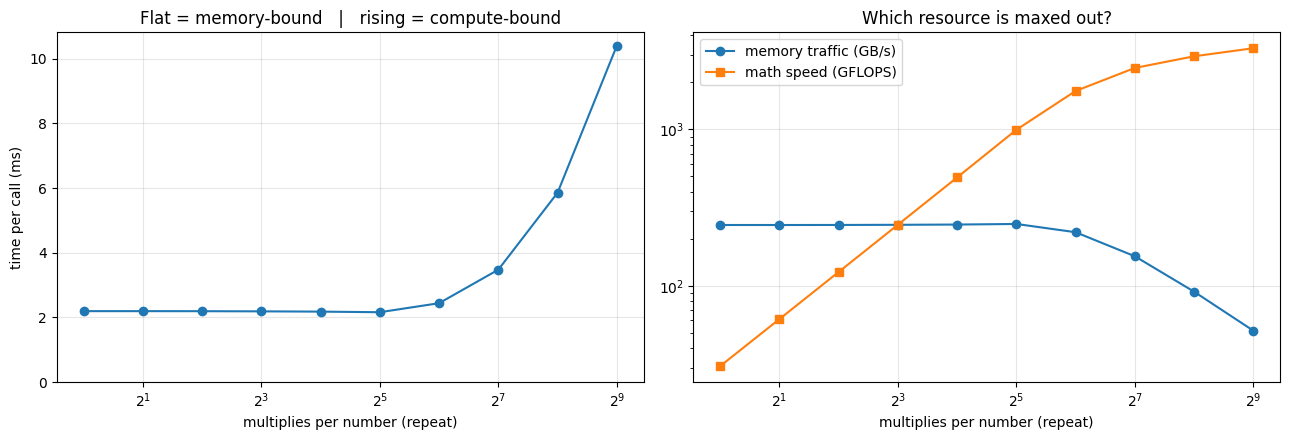

At repeat=1 (like ReLU, add, dropout) the GPU used 0.9% of its math capacity.


In [ ]:
reps = [r["repeat"] for r in rows]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(reps, [r["ms"] for r in rows], "o-")
ax[0].set_xscale("log", base=2)
ax[0].set_xlabel("multiplies per number (repeat)"); ax[0].set_ylabel("time per call (ms)")
ax[0].set_title("Flat = memory-bound   |   rising = compute-bound")
ax[0].set_ylim(bottom=0); ax[0].grid(alpha=.3)

ax[1].plot(reps, [r["GBs"] for r in rows], "o-", label="memory traffic (GB/s)")
ax[1].plot(reps, [r["GFLOPS"] for r in rows], "s-", label="math speed (GFLOPS)")
ax[1].set_xscale("log", base=2); ax[1].set_yscale("log")
ax[1].set_xlabel("multiplies per number (repeat)")
ax[1].set_title("Which resource is maxed out?"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

peak = max(r["GFLOPS"] for r in rows)
print(f"At repeat=1 (like ReLU, add, dropout) the GPU used {100*rows[0]['GFLOPS']/peak:.1f}% of its math capacity.")

**What it means:**

- **Left plot:** the flat part is the memory-bound region. Doing 32 multiplies costs about the same as doing 1, because the GPU spends that time waiting for data either way.
- **Right plot:** on the left, memory traffic (GB/s) is maxed out while math speed is low. On the right it flips: math speed hits its ceiling and memory traffic drops.
- **The bend** is where FLOPs per byte ≈ the GPU's math speed ÷ its memory speed. On a T4, memory delivers about 30 billion numbers per second while the math units can do about 4 trillion multiplies per second, so each number can absorb roughly 100+ multiplies "for free". The article's A100 bent at about 64.
- The top GFLOPS you measured is roughly **half the T4 datasheet number** (8.1 TFLOPS). Datasheets count a fused multiply-add as 2 FLOPs, and we only do plain multiplies. The article has the same footnote for the A100.
- **The real lesson:** everyday operations like ReLU, add and dropout do about 1 FLOP per number. They live at the far left of this plot and use only a tiny fraction of the GPU's math. They are **memory-bound**.

## Part 2: Kernel fusion

In normal PyTorch ("**eager mode**"), `x.cos().cos()` runs as **2 kernels**: read x → cos → write a temporary → read the temporary → cos → write. That is **4 memory trips**.

`torch.compile` **fuses** them into **1 kernel**: read x → cos → cos → write. That is **2 memory trips**.

**Expect:** eager `cos().cos()` takes about 2× as long as one `cos()`. Compiled `cos().cos()` takes about the same as one `cos()`.

In [ ]:
x = torch.randn(2**26, device=dev)

def cos_once(x):  return x.cos()
def cos_twice(x): return x.cos().cos()

torch._dynamo.reset()
cos_twice_fused = torch.compile(cos_twice)

versions = [("x.cos()         eager",    lambda: cos_once(x)),
            ("x.cos().cos()   eager",    lambda: cos_twice(x)),
            ("x.cos().cos()   compiled", lambda: cos_twice_fused(x))]

times = {}
print(f"{'version':28s} {'time':>9s} {'vs one cos':>11s} {'GPU kernels':>12s}")
for label, fn in versions:
    t = bench(fn)
    times[label] = t
    print(f"{label:28s} {t*1e3:6.2f} ms {t/times[versions[0][0]]:10.2f}x {len(gpu_kernels(fn)):12d}")

print("\nName of the fused kernel:", gpu_kernels(lambda: cos_twice_fused(x)))
results["exp2_fusion_ms"] = {"cos_eager": times[versions[0][0]] * 1e3,
                             "cos_cos_eager": times[versions[1][0]] * 1e3,
                             "cos_cos_compiled": times[versions[2][0]] * 1e3}

version                           time  vs one cos  GPU kernels
x.cos()         eager          2.28 ms       1.00x            1
x.cos().cos()   eager          4.57 ms       2.00x            2
x.cos().cos()   compiled       2.12 ms       0.93x            1

Name of the fused kernel: ['triton_poi_fused_cos_0']


**If memory is the real cost, then *which* math you do should barely matter.** Next we time 6 different elementwise operations, from a trivial `x * 2` to a much more complex GELU.

**Expect:** all of them take about the same time, at about the same GB/s.

In [ ]:
ops = {
    "x * 2":   lambda: x * 2,
    "relu":    lambda: F.relu(x),
    "gelu":    lambda: F.gelu(x),
    "sigmoid": lambda: torch.sigmoid(x),
    "exp":     lambda: torch.exp(x),
    "cos":     lambda: torch.cos(x),
}
bytes_moved = 2 * x.numel() * 4
results["exp2_activations_ms"] = {}
for name, fn in ops.items():
    t = bench(fn)
    results["exp2_activations_ms"][name] = t * 1e3
    print(f"{name:8s} {t*1e3:6.2f} ms   {bytes_moved/t/1e9:5.0f} GB/s")

x * 2      2.30 ms     233 GB/s
relu       2.31 ms     233 GB/s
gelu       2.28 ms     236 GB/s
sigmoid    2.28 ms     235 GB/s
exp        2.30 ms     234 GB/s
cos        2.28 ms     236 GB/s


**What it means:** GELU does far more math than ReLU, yet costs about the same, because both are waiting on memory. And fusing `cos().cos()` cut the time roughly in half without changing any math. That is why the article calls operator fusion *the* most important optimization in deep learning compilers, and why `torch.compile` speeds models up.

## Part 3: Overhead

Overhead is time spent on neither math nor memory: Python running your line of code, PyTorch deciding which kernel to use, and the cost of launching that kernel on the GPU.

### 3a. How slow is Python compared to the GPU?

In [ ]:
n = 10_000_000
a = 0.0
t0 = time.perf_counter()
for _ in range(n):
    a = a + 1.0
py_adds_per_s = n / (time.perf_counter() - t0)
gpu_ops_per_s = max(r["GFLOPS"] for r in results["exp1_repeat"]) * 1e9

print(f"Python:            {py_adds_per_s/1e6:6.0f} million additions per second")
print(f"GPU (Part 1 peak): {gpu_ops_per_s/1e12:6.1f} trillion multiplies per second")
print(f"=> In the time Python does ONE addition, this GPU can do about {gpu_ops_per_s/py_adds_per_s:,.0f} operations.")
results["exp3_python_adds_per_s"] = py_adds_per_s

Python:                 6 million additions per second
GPU (Part 1 peak):    3.3 trillion multiplies per second
=> In the time Python does ONE addition, this GPU can do about 580,783 operations.


### 3b. Shrink the tensor and watch the time stop shrinking

We time `x + 1` on tensors from 1 number up to 67 million numbers.

**Expect:** for small tensors the time is **flat**, around 5–20 µs (microseconds) whatever the size. That flat floor is pure overhead. Only for large tensors does the time grow with size, which is the memory-bound region.

           1 numbers        15.1 µs per op      0.00 GB/s
           4 numbers        15.3 µs per op      0.00 GB/s
          16 numbers        15.4 µs per op      0.01 GB/s
          64 numbers        14.8 µs per op      0.03 GB/s
         256 numbers        15.5 µs per op      0.13 GB/s
       1,024 numbers        18.6 µs per op      0.44 GB/s
       4,096 numbers        16.5 µs per op      1.99 GB/s
      16,384 numbers        15.8 µs per op      8.32 GB/s
      65,536 numbers        15.1 µs per op     34.76 GB/s
     262,144 numbers        17.1 µs per op    122.32 GB/s
   1,048,576 numbers        36.8 µs per op    228.24 GB/s
   4,194,304 numbers       145.0 µs per op    231.46 GB/s
  16,777,216 numbers       576.0 µs per op    233.00 GB/s
  67,108,864 numbers      2301.8 µs per op    233.24 GB/s


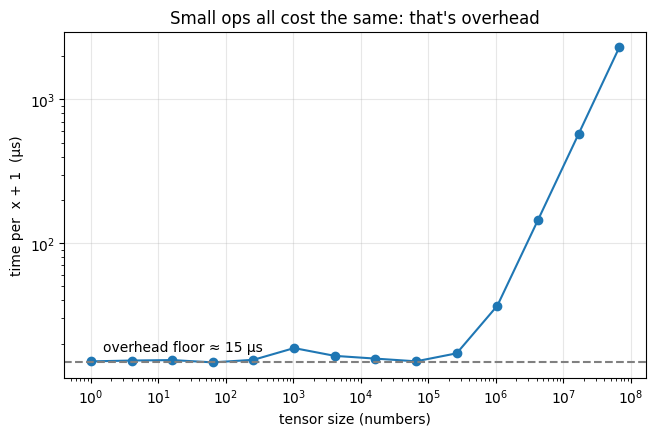

In [ ]:
rows = []
for k in range(0, 27, 2):                  # 1, 4, 16, ... 67 million numbers
    n = 2**k
    x = torch.randn(n, device=dev)
    t = bench(lambda: x + 1, target_seconds=0.15)
    rows.append({"numbers": n, "us": t * 1e6, "GBs": 2 * n * 4 / t / 1e9})
    print(f"{n:>12,d} numbers   {t*1e6:9.1f} µs per op   {2*n*4/t/1e9:7.2f} GB/s")
results["exp3_size_sweep"] = rows

floor = min(r["us"] for r in rows)
plt.figure(figsize=(7.5, 4.5))
plt.loglog([r["numbers"] for r in rows], [r["us"] for r in rows], "o-")
plt.axhline(floor, ls="--", c="gray")
plt.text(1.5, floor * 1.2, f"overhead floor ≈ {floor:.0f} µs")
plt.xlabel("tensor size (numbers)"); plt.ylabel("time per  x + 1  (µs)")
plt.title("Small ops all cost the same: that's overhead"); plt.grid(alpha=.3)
plt.show()

**What it means:** adding 1 to one number and adding 1 to a million numbers take nearly the same time, because the cost is the paperwork around the operation, not the work itself. A model made of many tiny operations leaves the GPU idle, which the article calls an "expensive paperweight".

### 3c. The batch-size test from the article

If doubling the batch size barely changes the runtime, you are overhead-bound. Here is a small 3-layer network.

**Expect:** the time per forward pass stays nearly flat from batch 1 up to the low thousands, so the time *per sample* keeps dropping.

In [ ]:
model = torch.nn.Sequential(
    torch.nn.Linear(256, 256), torch.nn.ReLU(),
    torch.nn.Linear(256, 256), torch.nn.ReLU(),
    torch.nn.Linear(256, 10),
).to(dev).eval()

rows = []
with torch.no_grad():
    for batch in [1, 4, 16, 64, 256, 1024, 4096, 16384, 65536]:
        inp = torch.randn(batch, 256, device=dev)
        t = bench(lambda: model(inp), target_seconds=0.15)
        rows.append({"batch": batch, "us": t * 1e6})
        print(f"batch {batch:6d}: {t*1e6:8.1f} µs per forward pass   ({t*1e6/batch:8.3f} µs per sample)")
results["exp3_batch_sweep"] = rows

batch      1:    146.0 µs per forward pass   ( 146.041 µs per sample)
batch      4:    146.1 µs per forward pass   (  36.517 µs per sample)
batch     16:    143.0 µs per forward pass   (   8.936 µs per sample)
batch     64:    175.4 µs per forward pass   (   2.741 µs per sample)
batch    256:    187.1 µs per forward pass   (   0.731 µs per sample)
batch   1024:    179.9 µs per forward pass   (   0.176 µs per sample)
batch   4096:    474.9 µs per forward pass   (   0.116 µs per sample)
batch  16384:   1886.7 µs per forward pass   (   0.115 µs per sample)
batch  65536:   7581.6 µs per forward pass   (   0.116 µs per sample)


### 3d. Fixing overhead with CUDA Graphs

A **CUDA Graph** records a whole sequence of GPU kernel launches once, then **replays** all of them with a single command. During replay, Python and PyTorch's per-operation bookkeeping are skipped entirely.

We use a deeper network here, with 20 layers and about 40 tiny GPU operations, so launch overhead clearly dominates. We compare three versions:
- **eager:** normal PyTorch. Each operation pays the ~14 µs overhead you measured in 3b.
- **torch.compile:** fuses each bias + ReLU, but still launches one kernel per matmul from Python, and adds its own checks on every call.
- **CUDA Graph:** captured once, then replayed with one call.

**Expect** at batch 16: the CUDA Graph is several times faster than eager. torch.compile helps only a little here, or is even slower, because its own per-call checks cost time on Colab's slow CPU.

In [ ]:
layers = []
for _ in range(20):
    layers += [torch.nn.Linear(256, 256), torch.nn.ReLU()]
deep = torch.nn.Sequential(*layers).to(dev).eval()
inp = torch.randn(16, 256, device=dev)
res = {}

with torch.no_grad():
    res["eager"] = bench(lambda: deep(inp)) * 1e6
    n_kernels = len(gpu_kernels(lambda: deep(inp)))

    torch._dynamo.reset()
    deep_compiled = torch.compile(deep)
    res["compiled"] = bench(lambda: deep_compiled(inp)) * 1e6

    # CUDA Graph: warm up on a side stream, capture once, then replay.
    static_in = inp.clone()
    side = torch.cuda.Stream()
    side.wait_stream(torch.cuda.current_stream())
    with torch.cuda.stream(side):
        for _ in range(3):
            deep(static_in)
    torch.cuda.current_stream().wait_stream(side)
    graph = torch.cuda.CUDAGraph()
    with torch.cuda.graph(graph):
        static_out = deep(static_in)        # recorded, not run
    res["cuda_graph"] = bench(lambda: graph.replay()) * 1e6

    graph.replay(); torch.cuda.synchronize()
    max_err = (static_out - deep(static_in)).abs().max().item()

print(f"Eager launches {n_kernels} GPU kernels per forward pass.\n")
for k, v in res.items():
    print(f"{k:11s} {v:8.1f} µs per forward pass   ({res['eager']/v:4.1f}x vs eager)")
print(f"\nCUDA Graph gives the same answer as eager: max difference = {max_err:.1e}")
results["exp3_overhead_fix_us"] = res

W1014 00:41:15.821000 2174 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


Eager launches 40 GPU kernels per forward pass.

eager         1103.4 µs per forward pass   ( 1.0x vs eager)
compiled      1028.7 µs per forward pass   ( 1.1x vs eager)
cuda_graph     161.0 µs per forward pass   ( 6.9x vs eager)

CUDA Graph gives the same answer as eager: max difference = 0.0e+00


**What it means:** replaying a graph pays the launch cost once for the whole sequence, not once per operation. `torch.compile(model, mode="reduce-overhead")` does this capture for you automatically. CUDA Graphs is the last fix in your playbook's answer to "Training is slower than expected".

If torch.compile came out *slower* than eager, that is a real result, not a bug. For tiny workloads on a slow CPU, the compiler's own per-call checks can cost more than the launches it saves. The lesson: always measure.

## Part 4: Compute-bound: matrix multiplies and Tensor Cores

A matrix multiply of two n × n matrices does **2n³ FLOPs** but moves only **3n² numbers**. Its arithmetic intensity grows with n, so big matmuls are compute-bound. We compare **fp32** (regular 32-bit math on general-purpose CUDA cores) with **fp16** (16-bit math, which can use the special **Tensor Cores**).

**Expect:**
- Small n (128–256): low TFLOPS. The matmul is too small to keep the GPU busy, so overhead and memory dominate.
- Large n: TFLOPS climbs toward a ceiling, which means compute-bound.
- fp16 is **several times faster** than fp32 at large sizes. That is the Tensor Cores at work, and it is why mixed precision (AMP) speeds up training.

This takes about a minute.

fp32  n=  128       0.021 ms     0.20 TFLOPS   intensity     21 FLOPs/byte
fp32  n=  256       0.032 ms     1.05 TFLOPS   intensity     43 FLOPs/byte
fp32  n=  512       0.071 ms     3.77 TFLOPS   intensity     85 FLOPs/byte
fp32  n= 1024       0.701 ms     3.06 TFLOPS   intensity    171 FLOPs/byte
fp32  n= 2048       5.165 ms     3.33 TFLOPS   intensity    341 FLOPs/byte
fp32  n= 4096      40.223 ms     3.42 TFLOPS   intensity    683 FLOPs/byte
fp32  n= 8192     337.739 ms     3.26 TFLOPS   intensity   1365 FLOPs/byte
fp16  n=  128       0.023 ms     0.18 TFLOPS   intensity     43 FLOPs/byte
fp16  n=  256       0.026 ms     1.31 TFLOPS   intensity     85 FLOPs/byte
fp16  n=  512       0.024 ms    11.34 TFLOPS   intensity    171 FLOPs/byte
fp16  n= 1024       0.105 ms    20.54 TFLOPS   intensity    341 FLOPs/byte
fp16  n= 2048       0.971 ms    17.69 TFLOPS   intensity    683 FLOPs/byte
fp16  n= 4096       7.295 ms    18.84 TFLOPS   intensity   1365 FLOPs/byte
fp16  n= 8192      53.672

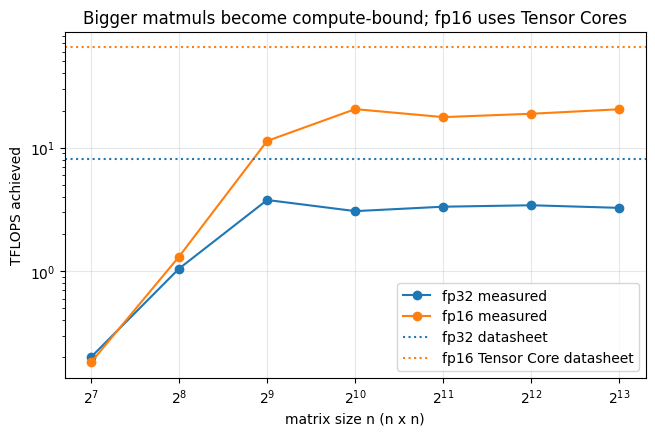

In [ ]:
rows = []
for dtype, label in [(torch.float32, "fp32"), (torch.float16, "fp16")]:
    for n in [128, 256, 512, 1024, 2048, 4096, 8192]:
        a = torch.randn(n, n, device=dev, dtype=dtype)
        b = torch.randn(n, n, device=dev, dtype=dtype)
        t = bench(lambda: a @ b, target_seconds=0.2, trials=3)
        flops = 2 * n**3
        bytes_moved = 3 * n * n * a.element_size()
        rows.append({"dtype": label, "n": n, "ms": t * 1e3, "GFLOPS": flops / t / 1e9,
                     "intensity": flops / bytes_moved})
        print(f"{label}  n={n:5d}   {t*1e3:9.3f} ms   {flops/t/1e12:6.2f} TFLOPS   "
              f"intensity {flops/bytes_moved:6.0f} FLOPs/byte")
    del a, b
results["exp4_matmul"] = rows

plt.figure(figsize=(7.5, 4.5))
for label, color in [("fp32", "C0"), ("fp16", "C1")]:
    pts = [row for row in rows if row["dtype"] == label]
    plt.plot([row["n"] for row in pts], [row["GFLOPS"] / 1e3 for row in pts], "o-", c=color, label=f"{label} measured")
if spec:
    plt.axhline(spec["fp32_TFLOPS"], ls=":", c="C0", label="fp32 datasheet")
    plt.axhline(spec["fp16_tensor_TFLOPS"], ls=":", c="C1", label="fp16 Tensor Core datasheet")
plt.xscale("log", base=2); plt.yscale("log")
plt.xlabel("matrix size n (n x n)"); plt.ylabel("TFLOPS achieved")
plt.title("Bigger matmuls become compute-bound; fp16 uses Tensor Cores")
plt.legend(); plt.grid(alpha=.3); plt.show()

**What it means:** large matmuls are the one place the GPU actually runs near its math limit. The only way to make them much faster is faster math: lower precision on Tensor Cores (fp16/bf16), or a bigger GPU (the article's joke: "give Nvidia more money"). Don't worry if you're well below the datasheet number. A Colab T4 is power-limited and slows its clock under heavy load.

## Part 5: The roofline chart

Everything you measured, on one chart:
- **x-axis:** arithmetic intensity, meaning how much math is done per byte moved.
- **y-axis:** how fast the GPU actually ran, in GFLOPS.
- **Slanted line:** the memory roof. Below the bend, speed is capped by bandwidth × intensity.
- **Flat lines:** the compute roofs, one for fp32 and a higher one for fp16 Tensor Cores.

Every point sits under the roof. The roof segment a point sits under tells you what limits it. The roofs are drawn from your **own** best measurements.

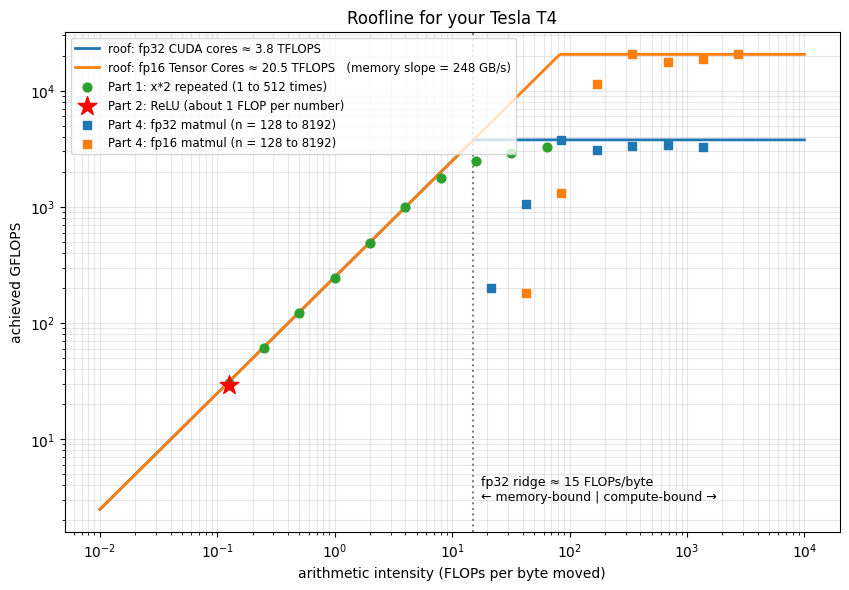

In [ ]:
import numpy as np

bw_GBs   = max(r["GBs"] for r in results["exp1_repeat"])
fp32_top = max(r["GFLOPS"] for r in results["exp4_matmul"] if r["dtype"] == "fp32")
fp16_top = max(r["GFLOPS"] for r in results["exp4_matmul"] if r["dtype"] == "fp16")

I = np.logspace(-2, 4, 400)                   # FLOPs per byte
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot(I, np.minimum(bw_GBs * I, fp32_top), c="C0", lw=2,
        label=f"roof: fp32 CUDA cores ≈ {fp32_top/1e3:.1f} TFLOPS")
ax.plot(I, np.minimum(bw_GBs * I, fp16_top), c="C1", lw=2,
        label=f"roof: fp16 Tensor Cores ≈ {fp16_top/1e3:.1f} TFLOPS   (memory slope = {bw_GBs:.0f} GB/s)")

e1 = results["exp1_repeat"]
ax.scatter([r["intensity"] for r in e1], [r["GFLOPS"] for r in e1], c="C2", s=40, zorder=3,
           label="Part 1: x*2 repeated (1 to 512 times)")
relu_ms = results["exp2_activations_ms"]["relu"]
ax.scatter([1/8], [2**26 / (relu_ms / 1e3) / 1e9], c="red", marker="*", s=200, zorder=4,
           label="Part 2: ReLU (about 1 FLOP per number)")
for lbl, c in [("fp32", "C0"), ("fp16", "C1")]:
    pts = [r for r in results["exp4_matmul"] if r["dtype"] == lbl]
    ax.scatter([r["intensity"] for r in pts], [r["GFLOPS"] for r in pts], c=c, marker="s", s=40,
               zorder=3, label=f"Part 4: {lbl} matmul (n = 128 to 8192)")

ridge = fp32_top / bw_GBs
ax.axvline(ridge, ls=":", c="gray")
ax.text(ridge * 1.15, 3, f"fp32 ridge ≈ {ridge:.0f} FLOPs/byte\n← memory-bound | compute-bound →", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("arithmetic intensity (FLOPs per byte moved)"); ax.set_ylabel("achieved GFLOPS")
ax.set_title(f"Roofline for your {gpu}")
ax.legend(loc="upper left", fontsize=8.5); ax.grid(alpha=.3, which="both")
plt.show()

**How to read it:**
- **ReLU** (the red star) sits far left, on the slanted memory roof. It is memory-bound, and no amount of extra compute power helps it. Only fusion helps, because fusion removes memory trips.
- The **Part 1** points climb the slope, then flatten. That is the bend you saw earlier. They level off below the fp32 roof because they do plain multiplies, while matmuls get 2 FLOPs per instruction from multiply-adds.
- **Small matmuls** sit below the roof because overhead dominates. **Big matmuls** reach the flat compute roofs, and the fp16 roof is far higher. That gap is the case for AMP.

## Part 6: A real layer: the BERT MLP block, eager vs compiled

This is the feed-forward block from BERT-base: `LayerNorm(x + (GELU(x·W1 + b1)·W2 + b2))` on 4,096 tokens in fp16. It has two big matmuls (compute-bound) and several elementwise steps (memory-bound).

**Expect:** compiled is faster, but **not** 2×, because the matmuls dominate and fusion can't speed them up. The compiled version launches **fewer kernels**, since bias + GELU and residual + LayerNorm get fused. This mirrors the article's BERT breakdown: non-matmul ops are a tiny share of the FLOPs but a real share of the time.

In [ ]:
D, H, T = 768, 3072, 4096                     # BERT-base width, MLP width, tokens (e.g. batch 8 x 512)
h16 = dict(device=dev, dtype=torch.float16)
xb   = torch.randn(T, D, **h16)
w1   = torch.randn(D, H, **h16) * 0.02; b1 = torch.zeros(H, **h16)
w2   = torch.randn(H, D, **h16) * 0.02; b2 = torch.zeros(D, **h16)
ln_w = torch.ones(D, **h16);            ln_b = torch.zeros(D, **h16)

def mlp_block(x):
    h = F.gelu(x @ w1 + b1)
    y = h @ w2 + b2
    return F.layer_norm(x + y, (D,), ln_w, ln_b)

torch._dynamo.reset()
mlp_block_compiled = torch.compile(mlp_block)

t_eager = bench(lambda: mlp_block(xb))
t_comp  = bench(lambda: mlp_block_compiled(xb))
k_eager = gpu_kernels(lambda: mlp_block(xb))
k_comp  = gpu_kernels(lambda: mlp_block_compiled(xb))

print(f"eager:    {t_eager*1e3:6.3f} ms   {len(k_eager)} GPU kernels")
print(f"compiled: {t_comp*1e3:6.3f} ms   {len(k_comp)} GPU kernels   ({t_eager/t_comp:.2f}x faster)")
print("\neager kernels:");    [print("  ", k[:90]) for k in k_eager]
print("compiled kernels:");   [print("  ", k[:90]) for k in k_comp]
results["exp6_block_ms"] = {"eager": t_eager * 1e3, "compiled": t_comp * 1e3,
                            "kernels_eager": len(k_eager), "kernels_compiled": len(k_comp)}

eager:     2.962 ms   8 GPU kernels
compiled:  2.581 ms   5 GPU kernels   (1.15x faster)

eager kernels:
   turing_fp16_s1688gemm_fp16_256x128_ldg8_f2f_stages_32x1_nn
   void at::native::elementwise_kernel<128, 4, at::native::gpu_kernel_impl_nocast<at::native:
   void at::native::vectorized_elementwise_kernel<4, at::native::GeluCUDAKernelImpl(at::Tenso
   Memset (Device)
   turing_fp16_s1688gemm_fp16_128x128_ldg8_f2f_nn
   void at::native::elementwise_kernel<128, 4, at::native::gpu_kernel_impl_nocast<at::native:
   void at::native::vectorized_elementwise_kernel<4, at::native::CUDAFunctor_add<c10::Half>, 
   void at::native::(anonymous namespace)::vectorized_layer_norm_kernel<c10::Half, float, fal
compiled kernels:
   turing_fp16_s1688gemm_fp16_256x128_ldg8_f2f_stages_32x1_nn
   triton_poi_fused_add_gelu_0
   Memset (Device)
   turing_fp16_s1688gemm_fp16_128x128_ldg8_f2f_nn
   triton_per_fused_add_native_layer_norm_1


**What it means:** in the kernel lists, look for names with `gemm` or `mm`. Those are the matmuls, and they appear in both versions. The compiled list replaces separate add, gelu, add and layer_norm kernels with a couple of `triton_..._fused_...` kernels. This is the same thing you'll measure in perf-lab experiment 03 (AMP + `torch.compile`).

## Part 7: Your key numbers (save these)

In [ ]:
e1 = results["exp1_repeat"]
base = e1[0]["ms"]
peak = max(r["GFLOPS"] for r in e1)
bw = max(r["GBs"] for r in e1)
bend_i = next((i for i, r in enumerate(e1) if r["ms"] > 1.2 * base), None)
bend = f"between {e1[bend_i-1]['repeat']} and {e1[bend_i]['repeat']}" if bend_i else "beyond 512"
predicted = peak / (bw / 8)          # multiplies the GPU can do per number it loads
m = results["exp4_matmul"]
f = results["exp2_fusion_ms"]
oh = results.get("exp3_overhead_fix_us", {})
blk = results.get("exp6_block_ms", {})

lines = [
    f"GPU: {gpu}   PyTorch: {torch.__version__}",
    f"Memory bandwidth reached:            {max(r['GBs'] for r in e1):.0f} GB/s"
        + (f"   (datasheet {spec['bandwidth_GBs']} GB/s)" if spec else ""),
    f"Memory->compute bend (Part 1):       {bend} multiplies per number (theory: ~{predicted:.0f})",
    f"Math used by a 1-op elementwise op:  {100 * e1[0]['GFLOPS'] / peak:.1f}% of peak",
    f"cos().cos() eager -> compiled:       {f['cos_cos_eager']:.2f} ms -> {f['cos_cos_compiled']:.2f} ms",
    f"GELU vs ReLU time:                   {results['exp2_activations_ms']['gelu']:.2f} ms vs {results['exp2_activations_ms']['relu']:.2f} ms",
    f"Overhead floor per tiny op:          {min(r['us'] for r in results['exp3_size_sweep']):.1f} µs",
    f"20-layer MLP eager -> CUDA Graph:   {oh.get('eager', float('nan')):.1f} µs -> {oh.get('cuda_graph', float('nan')):.1f} µs",
    f"Best matmul: fp32 {max(r['GFLOPS'] for r in m if r['dtype'] == 'fp32')/1e3:.1f} TFLOPS, "
        f"fp16 {max(r['GFLOPS'] for r in m if r['dtype'] == 'fp16')/1e3:.1f} TFLOPS",
    f"BERT MLP block eager -> compiled:    {blk.get('eager', float('nan')):.2f} ms -> {blk.get('compiled', float('nan')):.2f} ms",
]
print("\n".join(lines))
results["summary"] = lines

with open("brrr_results.json", "w") as fh:
    json.dump(results, fh, indent=2)
print("\nSaved brrr_results.json")
try:
    from google.colab import files
    files.download("brrr_results.json")       # downloads it to your computer
except ImportError:
    pass

GPU: Tesla T4   PyTorch: 2.11.0+cu130
Memory bandwidth reached:            248 GB/s   (datasheet 320 GB/s)
Memory->compute bend (Part 1):       between 64 and 128 multiplies per number (theory: ~106)
Math used by a 1-op elementwise op:  0.9% of peak
cos().cos() eager -> compiled:       4.57 ms -> 2.12 ms
GELU vs ReLU time:                   2.28 ms vs 2.31 ms
Overhead floor per tiny op:          14.8 µs
20-layer MLP eager -> CUDA Graph:   1103.4 µs -> 161.0 µs
Best matmul: fp32 3.8 TFLOPS, fp16 20.5 TFLOPS
BERT MLP block eager -> compiled:    2.96 ms -> 2.58 ms

Saved brrr_results.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Say it out loud (interview practice)

Fill the blanks with **your** numbers from the cell above, then practise saying each one in under 30 seconds:

1. **Memory-bound:** "On a T4, an elementwise op like ReLU used under ___% of the GPU's math capacity. It is limited by memory bandwidth, which I measured at ___ GB/s. Even GELU cost the same as ReLU."
2. **Fusion:** "Fusing `cos().cos()` with `torch.compile` took it from ___ ms to ___ ms. The math didn't change; one round trip to memory disappeared."
3. **Overhead:** "Below about a hundred thousand elements, every op costs a flat ___ µs. That is Python, the PyTorch dispatcher and the kernel launch. A CUDA Graph cut a 20-layer MLP from ___ µs to ___ µs."
4. **Compute-bound:** "Large matmuls reached ___ TFLOPS in fp16 versus ___ in fp32, thanks to Tensor Cores. That's why AMP speeds up compute-bound training."
5. **Roofline:** "The ridge point on my GPU is about ___ FLOPs per byte. Anything below that is memory-bound, so the fix is fusion, not a faster GPU."

**Next step:** save this notebook (File → Save a copy in GitHub, or download the .ipynb) into your `pytorch-training-perf-lab` repo as `00_brrr_first_principles.ipynb`, with `brrr_results.json` beside it. Then move on to experiment 01: profiling a real training step.